In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
# Load the dataset

file_path = "heart_disease_combined_raw(3).csv"

df = pd.read_csv('C:\\Users\\User\\Downloads\\heart+disease\\heart_disease_combined_raw(3).csv')

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (900, 77)


In [4]:
# Display first five records

print("First five records:")
display(df.head())

First five records:


,source,id,ccf,age,sex,painloc,painexer,relrest,pncaden,cp,...,rcaprox,rcadist,lvx1,lvx2,lvx3,lvx4,lvf,cathef,junk,name
0,Cleveland,1,0,63,1,-9,-9,-9,-9,1,...,1,1,1,1,1,1,1,-9.0,-9.0,name
1,Cleveland,2,0,67,1,-9,-9,-9,-9,4,...,1,1,1,1,1,1,1,-9.0,-9.0,name
2,Cleveland,3,0,67,1,-9,-9,-9,-9,4,...,2,2,1,1,1,7,3,-9.0,-9.0,name
3,Cleveland,4,0,37,1,-9,-9,-9,-9,3,...,1,1,1,1,1,1,1,-9.0,-9.0,name
4,Cleveland,6,0,41,0,-9,-9,-9,-9,2,...,1,1,1,1,1,1,1,-9.0,-9.0,name


In [5]:
# Create a copy for modelling

df_model = df.copy()

# Convert original target into binary classification target
# 0 = No Heart Disease
# 1 = Heart Disease Present

df_model["target"] = (df_model["num"] > 0).astype(int)

print("Binary target created successfully.")

print("\nTarget values:")
print(df_model["target"].unique())

Binary target created successfully.

Target values:
[0 1]


In [6]:
# Display target distribution

target_distribution = df_model["target"].value_counts().sort_index()

print("Target Distribution")
print("===================")

print(
    "No Heart Disease (0):",
    target_distribution.get(0, 0)
)

print(
    "Heart Disease (1):",
    target_distribution.get(1, 0)
)

Target Distribution
No Heart Disease (0): 404
Heart Disease (1): 496


In [7]:
# Select clinically relevant features for modelling

selected_features = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal"
]

print("Selected Features:")
print("==================")

for i, feature in enumerate(selected_features, start=1):
    print(f"{i}. {feature}")

print("\nTotal selected features:", len(selected_features))

Selected Features:
1. age
2. sex
3. cp
4. trestbps
5. chol
6. fbs
7. restecg
8. thalach
9. exang
10. oldpeak
11. slope
12. ca
13. thal

Total selected features: 13


In [8]:
# Create a description table for selected features

feature_description = pd.DataFrame({
    "Feature": [
        "age",
        "sex",
        "cp",
        "trestbps",
        "chol",
        "fbs",
        "restecg",
        "thalach",
        "exang",
        "oldpeak",
        "slope",
        "ca",
        "thal"
    ],
    
    "Description": [
        "Age of the patient",
        "Sex of the patient",
        "Chest pain type",
        "Resting blood pressure",
        "Serum cholesterol",
        "Fasting blood sugar",
        "Resting electrocardiographic result",
        "Maximum heart rate achieved",
        "Exercise-induced angina",
        "ST depression induced by exercise",
        "Slope of the peak exercise ST segment",
        "Number of major vessels",
        "Thalassemia-related measurement"
    ]
})

display(feature_description)

,Feature,Description
0,age,Age of the patient
1,sex,Sex of the patient
2,cp,Chest pain type
3,trestbps,Resting blood pressure
4,chol,Serum cholesterol
5,fbs,Fasting blood sugar
6,restecg,Resting electrocardiographic result
7,thalach,Maximum heart rate achieved
8,exang,Exercise-induced angina
9,oldpeak,ST depression induced by exercise


In [9]:
# Create feature matrix X and target vector y

X = df_model[selected_features].copy()

y = df_model["target"].copy()

print("Feature matrix X shape:", X.shape)
print("Target vector y shape:", y.shape)

Feature matrix X shape: (900, 13)
Target vector y shape: (900,)


In [10]:
# Display selected features and target

selected_data = X.copy()

selected_data["target"] = y

display(selected_data.head(10))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0,6,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,3,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0
5,56,1,2,120,236,0,0,178,0,0.8,1,0,3,0
6,62,0,4,140,268,0,2,160,0,3.6,3,2,3,1
7,57,0,4,120,354,0,0,163,1,0.6,1,0,3,0
8,63,1,4,130,254,0,2,147,0,1.4,2,1,7,1
9,53,1,4,140,203,1,2,155,1,3.1,3,0,7,1


In [11]:
# Check data types of selected features

print("Data types of selected features:")
print()

display(
    pd.DataFrame({
        "Feature": X.columns,
        "Data Type": X.dtypes.astype(str).values
    })
)

Data types of selected features:



,Feature,Data Type
0,age,int64
1,sex,int64
2,cp,int64
3,trestbps,int64
4,chol,int64
5,fbs,int64
6,restecg,int64
7,thalach,int64
8,exang,int64
9,oldpeak,float64


In [12]:
# Check missing values in selected features

missing_values = X.isnull().sum()

missing_table = pd.DataFrame({
    "Feature": X.columns,
    "Missing Values": missing_values.values,
    "Missing Percentage": (
        missing_values.values / len(X) * 100
    ).round(2)
})

display(missing_table)

,Feature,Missing Values,Missing Percentage
0,age,0,0.0
1,sex,0,0.0
2,cp,0,0.0
3,trestbps,0,0.0
4,chol,0,0.0
5,fbs,0,0.0
6,restecg,0,0.0
7,thalach,0,0.0
8,exang,0,0.0
9,oldpeak,0,0.0


In [13]:
# Handle missing values using median imputation

X = X.copy()

for column in X.columns:
    if X[column].isnull().sum() > 0:
        X[column] = X[column].fillna(X[column].median())

print("Missing-value treatment completed.")

print("\nRemaining missing values:")
print(X.isnull().sum().sum())

Missing-value treatment completed.

Remaining missing values:
0


In [14]:
# Check duplicate rows in the selected dataset

duplicate_count = X.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 2


In [15]:
# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data split completed successfully.")

print("\nTraining data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Data split completed successfully.

Training data:
X_train: (720, 13)
y_train: (720,)

Testing data:
X_test: (180, 13)
y_test: (180,)


In [16]:
# Compare class distribution before and after splitting

train_distribution = y_train.value_counts(normalize=True).sort_index() * 100
test_distribution = y_test.value_counts(normalize=True).sort_index() * 100

distribution_table = pd.DataFrame({
    "Class": ["No Heart Disease", "Heart Disease"],
    "Training (%)": [
        train_distribution.get(0, 0),
        train_distribution.get(1, 0)
    ],
    "Testing (%)": [
        test_distribution.get(0, 0),
        test_distribution.get(1, 0)
    ]
})

display(distribution_table.round(2))

,Class,Training (%),Testing (%)
0,No Heart Disease,44.86,45.0
1,Heart Disease,55.14,55.0


In [17]:
# Standardize features

scaler = StandardScaler()

# Fit scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature standardization completed.")
print()
print("Scaler was fitted only on training data.")
print("Testing data was transformed using training-set parameters.")

Feature standardization completed.

Scaler was fitted only on training data.
Testing data was transformed using training-set parameters.


In [18]:
# Convert standardized arrays back into DataFrames

X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=selected_features,
    index=X_train.index
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=selected_features,
    index=X_test.index
)

print("Standardized training data:")
display(X_train_scaled_df.head())

Standardized training data:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
217,-0.810469,-1.917114,0.807955,0.376454,0.423985,0.256616,1.602706,0.544717,0.519432,-0.056501,0.775665,1.266146,0.736052
880,0.365803,0.521617,0.807955,-0.018514,0.603958,0.256616,1.602706,-0.642373,0.092502,-0.056501,-1.360381,-0.694338,-0.941913
220,-1.345138,-1.917114,-0.283466,-0.265370,0.638239,0.256616,1.602706,1.001290,0.519432,-0.056501,0.581479,1.266146,0.736052
778,0.686604,0.521617,0.807955,0.475197,0.192591,0.256616,-0.673326,-0.414087,0.519432,0.856447,0.775665,-0.694338,-0.941913
687,-0.168866,0.521617,0.807955,0.302398,-1.658564,-3.069129,-0.673326,-0.003171,0.519432,0.673857,0.775665,-0.694338,1.295373


In [19]:
# Verify mean and standard deviation after scaling

scaling_check = pd.DataFrame({
    "Feature": selected_features,
    "Training Mean": X_train_scaled_df.mean().values,
    "Training Std": X_train_scaled_df.std().values
})

display(scaling_check.round(4))

,Feature,Training Mean,Training Std
0,age,0.0,1.0007
1,sex,0.0,1.0007
2,cp,-0.0,1.0007
3,trestbps,0.0,1.0007
4,chol,0.0,1.0007
5,fbs,-0.0,1.0007
6,restecg,-0.0,1.0007
7,thalach,0.0,1.0007
8,exang,0.0,1.0007
9,oldpeak,0.0,1.0007


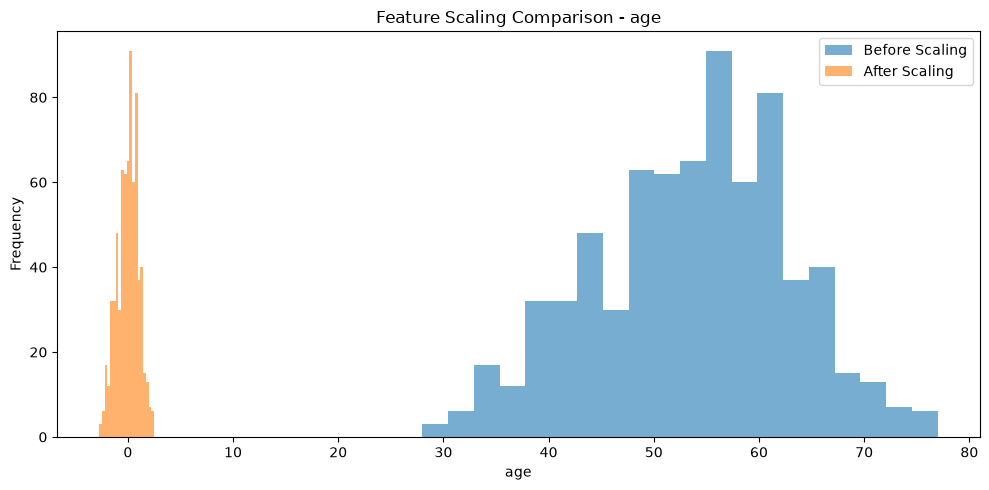

In [20]:
# Compare feature distributions before and after scaling

feature_to_check = "age"

plt.figure(figsize=(10, 5))

plt.hist(
    X_train[feature_to_check],
    bins=20,
    alpha=0.6,
    label="Before Scaling"
)

plt.hist(
    X_train_scaled_df[feature_to_check],
    bins=20,
    alpha=0.6,
    label="After Scaling"
)

plt.title(f"Feature Scaling Comparison - {feature_to_check}")
plt.xlabel(feature_to_check)
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()

In [21]:
# Verify that the scaler was fitted using training data only

train_mean_before_scaling = X_train.mean()
test_mean_before_scaling = X_test.mean()

train_mean_after_scaling = X_train_scaled_df.mean()
test_mean_after_scaling = X_test_scaled_df.mean()

print("Data Leakage Prevention Check")
print("=============================")

print("\nScaler fitting:")
print("Scaler fitted on X_train only.")

print("\nX_train transformation:")
print("X_train was transformed using parameters learned from X_train.")

print("\nX_test transformation:")
print("X_test was transformed using the same training parameters.")

print("\nNo information from X_test was used while fitting the scaler.")

Data Leakage Prevention Check

Scaler fitting:
Scaler fitted on X_train only.

X_train transformation:
X_train was transformed using parameters learned from X_train.

X_test transformation:
X_test was transformed using the same training parameters.

No information from X_test was used while fitting the scaler.


In [22]:
# Final modelling dataset summary

print("FINAL DATA PREPARATION SUMMARY")
print("==============================")

print("Original dataset:", df.shape)

print("Selected features:", len(selected_features))

print("Training samples:", X_train.shape[0])

print("Testing samples:", X_test.shape[0])

print("Training features:", X_train.shape[1])

print("Testing features:", X_test.shape[1])

print("Target classes:", sorted(y.unique()))

print("Missing values after treatment:", X.isnull().sum().sum())

FINAL DATA PREPARATION SUMMARY
Original dataset: (900, 77)
Selected features: 13
Training samples: 720
Testing samples: 180
Training features: 13
Testing features: 13
Target classes: [np.int64(0), np.int64(1)]
Missing values after treatment: 0


In [23]:
# Display final feature list used for modelling

final_feature_table = pd.DataFrame({
    "Feature Number": range(1, len(selected_features) + 1),
    "Feature Name": selected_features
})

display(final_feature_table)

,Feature Number,Feature Name
0,1,age
1,2,sex
2,3,cp
3,4,trestbps
4,5,chol
5,6,fbs
6,7,restecg
7,8,thalach
8,9,exang
9,10,oldpeak
